# RAG 과제 — Python 공식 튜토리얼 학습 도우미

## 목적
Python 공식 문서 5개를 실제로 크롤링해 출처를 보존하고, 질문과 관련된 문서를 검색한 뒤 한국어로 답변한다. 동일 질문의 **RAG 없이 / RAG 사용** 응답을 비교한다.

- 코퍼스: Python 3.13 한국어 튜토리얼의 입문·제어 흐름·자료 구조·모듈·예외
- 청킹: 절 제목 유지, 본문 900자, 150자 중첩
- 임베딩: `text-embedding-3-small`, 벡터 DB: Chroma cosine
- 생성 모델: `gpt-4o-mini`, temperature=0, 검색 문서 최대 4개
- 질문 10개: 문서에 답이 있는 질문 8개 + 문서에 없는 질문 2개

**실행 기본값은 저장 결과 확인이다.** `RUN_LIVE=True`로 바꾸면 실제 API 평가를 수행한다. 재크롤링은 `python crawl.py`로 명시적으로 수행한다.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

BASE = Path.cwd() if (Path.cwd() / "rag_pipeline.py").exists() else Path.cwd() / "Changyub"
import sys
sys.path.insert(0, str(BASE.resolve()))
from rag_pipeline import load_chunks, RAG
from evaluate_rag import evaluate
RESULT_DIR = BASE / "results"
RUN_LIVE = False
print("mode:", "LIVE evaluation" if RUN_LIVE else "saved results")

mode: saved results


## 1. 크롤링 원문과 출처
`crawl.py`는 robots.txt 확인 후 0.5초 이상의 간격으로 허용된 5개 URL만 수집한다. 내비게이션·푸터를 제거하고 절 제목, 문단, 코드 블록을 보존한다. raw HTML, 정제 TXT, 절별 JSON, URL·수집 시각·SHA-256을 저장했다. PSF 라이선스와 저작권 고지도 함께 보관한다.


In [2]:
manifest = json.loads((BASE / "source_data/manifest.json").read_text())
df_sources = pd.DataFrame(manifest)
display(df_sources[["id", "title", "chars", "section_count", "crawled_at", "url"]])
print("문서 수:", len(manifest), "| 본문 문자 수:", int(df_sources.chars.sum()))

,id,title,chars,section_count,crawled_at,url
0,introduction,3. 파이썬의 간략한 소개 — Python 3.13.16 문서,12242,6,2026-10-08T13:33:16+09:00,https://docs.python.org/ko/3.13/tutorial/intro...
1,controlflow,4. 기타 제어 흐름 도구 — Python 3.13.16 문서,26941,24,2026-10-08T13:33:17+09:00,https://docs.python.org/ko/3.13/tutorial/contr...
2,datastructures,5. 자료 구조 — Python 3.13.16 문서,16884,13,2026-10-08T13:33:18+09:00,https://docs.python.org/ko/3.13/tutorial/datas...
3,modules,6. 모듈 — Python 3.13.16 문서,15587,10,2026-10-08T13:33:19+09:00,https://docs.python.org/ko/3.13/tutorial/modul...
4,errors,8. 에러와 예외 — Python 3.13.16 문서,17195,11,2026-10-08T13:33:20+09:00,https://docs.python.org/ko/3.13/tutorial/error...


문서 수: 5 | 본문 문자 수: 88849


In [3]:
sample = json.loads((BASE / "source_data/datastructures.json").read_text())
print("원문 예시:", sample["title"])
print(sample["sections"][1]["text"][:650])

원문 예시: 5. 자료 구조 — Python 3.13.16 문서
The list data type has some more methods. Here are all
of the methods of list objects:

list. append ( value , / )

리스트의 끝에 항목을 더합니다. a[len(a):] = [x] 와 비슷합니다.

list. extend ( iterable , / )

리스트의 끝에 이터러블의 모든 항목을 덧붙여서 확장합니다. a[len(a):] = iterable 와 비슷합니다.

list. insert ( index , value , / )

주어진 위치에 항목을 삽입합니다. 첫 번째 인자는 삽입되는 요소가 갖게 될 인덱스입니다. 그래서 a.insert(0, x) 는 리스트의 처음에 삽입하고, a.insert(len(a), x) 는 a.append(x) 와 동등합니다.

list. remove ( value , / )

Remove the first item from the list whose value is equal to value .  It raises a ValueError if there is no such item.

list. pop ( index = -1 , / )

리스트에서 주어진 위치에 있는 항목을 삭제하고, 그 항목을 돌려줍니다. 인덱스를 지정하지 


## 2. 청크 생성
각 절을 독립적으로 나눠 절의 출처 링크와 제목을 유지한다. 본문이 900자를 넘으면 150자를 겹치게 분할한다. 최종 조각 뒤의 중복 꼬리 청크를 방지하고 `0 <= overlap < chunk_size`를 검증한다. 임베딩은 제목과 본문을 합친 텍스트에 적용되므로 전체 청크 길이는 제목 길이만큼 더 길다.


In [4]:
chunks = load_chunks(chunk_size=900, overlap=150)
df_chunks = pd.DataFrame(chunks)
print("청크 수:", len(chunks))
display(df_chunks.groupby("doc_id").size().rename("chunks"))
display(df_chunks[["id", "heading", "url", "text"]].head(3))

청크 수: 141


doc_id
controlflow       43
datastructures    28
errors            27
introduction      19
modules           24
Name: chunks, dtype: int64

,id,heading,url,text
0,introduction:0:0,3. 파이썬의 간략한 소개,https://docs.python.org/ko/3.13/tutorial/intro...,"3. 파이썬의 간략한 소개\n다음에 나올 예에서, 입력과 출력은 프롬프트( >>> ..."
1,introduction:1:0,3.1. 파이썬을 계산기로 사용하기,https://docs.python.org/ko/3.13/tutorial/intro...,3.1. 파이썬을 계산기로 사용하기\n몇 가지 간단한 파이썬 명령을 사용해봅시다. ...
2,introduction:2:0,3.1.1. 숫자,https://docs.python.org/ko/3.13/tutorial/intro...,3.1.1. 숫자\nThe interpreter acts as a simple ca...


## 3. 임베딩·벡터 DB·검색
문서를 32개씩 배치 임베딩하고 Chroma에 저장한다. 내용·모델·청킹 설정을 해시로 묶어 다른 실행의 DB와 섞이지 않게 했다. 같은 DB를 다시 열면 임베딩을 재생성하지 않는다.

첫 실험은 벡터 검색만 사용했다. 같은 절이 검색 결과를 독점하면서 `sorted()` 설명을 놓쳤고, 세부 절에서 상위 개념을 빠뜨렸다. 이를 다음과 같이 보완했다.

1. 의미 기반 벡터 검색과 식별자·숫자를 보존하는 BM25 검색 순위를 RRF로 합친다.
2. 같은 절에서 최대 2개 청크를 우선 선택한다.
3. 함수 비교 질문에서는 각 함수의 동작·반환값을 별도로 검색하고 해당 식별자와 맞는 텍스트를 보충한다.
4. 가장 높은 순위의 세부 절에 대해 상위 절의 설명을 최대 한 청크 함께 가져온다.

거리와 RRF 점수는 서로 다른 지표이며 점수 자체가 사실성을 보장하지 않는다.


In [5]:
if RUN_LIVE:
    summary = evaluate()
else:
    summary = json.loads((RESULT_DIR / "rag_summary.json").read_text())
answers = json.loads((RESULT_DIR / "rag_answers.json").read_text())
comparison = pd.read_csv(RESULT_DIR / "rag_comparison.csv")
display(pd.Series(summary))

executed_at                                                 2026-10-08T15:06:29+09:00
chat_model                                                                gpt-4o-mini
embedding_model                                                text-embedding-3-small
top_k                                                                               4
retrieval                           dense + BM25 RRF + function comparison subquer...
build                               {'chunks': 141, 'new_embeddings': 0, 'collecti...
questions                                                                          10
answer_count                                                                       20
retrieval_doc_hit_at_k                                                            1.0
retrieval_section_hit_at_k                                                        1.0
supported_answers_with_citations                                                    8
invalid_citation_count                                

In [6]:
q2 = next(a for a in answers if a["id"] == "Q2" and a["mode"] == "rag")
display(pd.DataFrame(q2["retrieved"])[["id", "heading", "distance", "rrf_score", "bm25_score", "url"]])
print(q2["answer"])
for source in q2["sources"]:
    print(f'[{source["citation"]}] {source["url"]}')

,id,heading,distance,rrf_score,bm25_score,url
0,datastructures:1:2,5.1. 리스트 더 보기,0.57015,0.032266,8.3472,https://docs.python.org/ko/3.13/tutorial/datas...
1,datastructures:1:1,5.1. 리스트 더 보기,0.55626,0.032522,15.9630,https://docs.python.org/ko/3.13/tutorial/datas...
2,datastructures:10:1,5.6. 루프 테크닉,NaN,0.014493,5.3612,https://docs.python.org/ko/3.13/tutorial/datas...
3,datastructures:12:1,5.8. 시퀀스와 다른 형들을 비교하기,0.64671,0.030331,6.7363,https://docs.python.org/ko/3.13/tutorial/datas...


`list.sort()`는 리스트의 항목들을 제자리에서 정렬하며, 반환값은 기본적으로 `None`입니다. 즉, 이 메서드는 리스트를 직접 수정하지만, 수정된 리스트를 반환하지 않습니다 [1]. 

반면에 `sorted()` 함수는 주어진 시퀀스를 정렬하여 새로운 리스트를 반환합니다. 이 함수는 원래 리스트를 변경하지 않고, 정렬된 새 리스트를 생성합니다 [3]. 

따라서, `list.sort()`는 원래 리스트를 변경하고 반환값이 `None`인 반면, `sorted()`는 원래 리스트를 변경하지 않고 정렬된 새 리스트를 반환합니다.
[1] https://docs.python.org/ko/3.13/tutorial/datastructures.html#more-on-lists
[3] https://docs.python.org/ko/3.13/tutorial/datastructures.html#looping-techniques


## 4. RAG 유무 비교와 평가 기준
두 조건에서 모델과 temperature, 질문을 동일하게 사용했다. RAG 조건은 검색 문서만 근거로 답하고 출처를 인용하며, 근거가 없으면 답변을 유보한다. No-RAG 조건은 학습된 지식으로 답변한다.

`expected_doc_hit`는 정답 문서가 검색 결과에 들어 있는지, `expected_section_hit`는 지정한 대표 절이 들어 있는지 측정한다. **이 값은 응답 정답률이 아니다.** 출처 번호 유효성과 응답 내용의 근거는 구분해 검토했다.

토큰은 각 응답 생성 당시 사용량이며, 캐시로 다시 표시한 경우 추가 호출 비용을 의미하지 않는다. 임베딩 토큰은 별도 API 로그에 기록돼 있다.


,id,mode,in_corpus,expected_doc_hit,expected_section_hit,citation_count,abstained,tokens,cached
0,Q1,no_rag,True,False,False,0,False,112,True
1,Q1,rag,True,True,True,1,False,1591,True
2,Q2,no_rag,True,False,False,0,False,104,True
3,Q2,rag,True,True,True,2,False,1804,False
4,Q3,no_rag,True,False,False,0,False,135,True
5,Q3,rag,True,True,True,1,False,2345,True
6,Q4,no_rag,True,False,False,0,False,200,True
7,Q4,rag,True,True,True,1,False,2034,True
8,Q5,no_rag,True,False,False,0,False,142,True
9,Q5,rag,True,True,True,1,False,2104,True


,tokens,latency_s
mode,,
no_rag,141.0,1.67
rag,1708.2,1.91


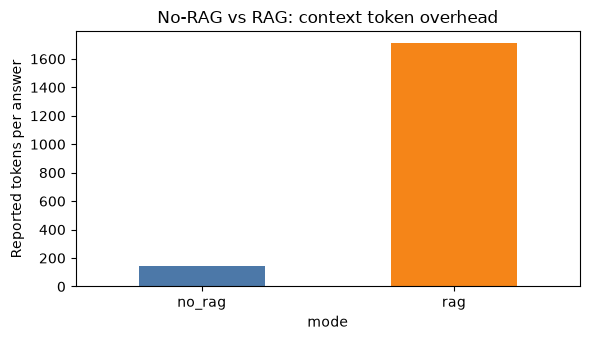

In [7]:
display(comparison[["id", "mode", "in_corpus", "expected_doc_hit", "expected_section_hit", "citation_count", "abstained", "tokens", "cached"]])
means = comparison.groupby("mode")[["tokens", "latency_s"]].mean().round(2)
display(means)
fig, ax = plt.subplots(figsize=(6, 3.5))
means["tokens"].reindex(["no_rag", "rag"]).plot.bar(ax=ax, rot=0, color=["#4C78A8", "#F58518"])
ax.set_ylabel("Reported tokens per answer")
ax.set_title("No-RAG vs RAG: context token overhead")
fig.tight_layout()
fig.savefig(RESULT_DIR / "RAG_tokens.png", dpi=160)
plt.show()

## 5. 전체 질문과 실제 응답
질문별로 두 응답과 RAG 출처를 확인한다. 원문을 바꾸거나 출력을 편집해서 결과를 만들지 않았으며, 실제 API 출력을 저장해 다시 보여준다.


In [8]:
for qid in comparison.id.drop_duplicates():
    pair = [a for a in answers if a["id"] == qid]
    display(Markdown(f"### {qid} — {pair[0]['question']}"))
    for answer in pair:
        display(Markdown(f"**{answer['mode']}**\n\n{answer['answer']}"))
        for source in answer["sources"]:
            display(Markdown(f"[{source['citation']}] [{source['heading']}]({source['url']})"))

### Q1 — 공식 튜토리얼에서 range(5)는 어떤 숫자를 만들며 끝값 5가 포함되나요?

**no_rag**

`range(5)`는 0부터 4까지의 숫자를 생성합니다. 끝값 5는 포함되지 않습니다. 즉, 결과는 0, 1, 2, 3, 4입니다.

**rag**

공식 튜토리얼에서 `range(5)`는 0부터 4까지의 숫자를 생성합니다. 끝값인 5는 포함되지 않습니다. 즉, 생성되는 수열은 0, 1, 2, 3, 4입니다 [1].

[1] [4.3. range() 함수](https://docs.python.org/ko/3.13/tutorial/controlflow.html#the-range-function)

### Q2 — list.sort()와 sorted()는 원래 리스트 변경과 반환값이 어떻게 다른가요?

...

**no_rag**

`select_related`와 `prefetch_related`는 Django ORM에서 데이터베이스 쿼리를 최적화하는 방법입니다.

- **select_related**: 외래 키 관계를 가진 객체를 한 번의 SQL 쿼리로 가져옵니다. JOIN을 사용하여 관련된 객체를 함께 가져오므로, 데이터베이스에 대한 쿼리 수를 줄일 수 있습니다. 주로 1:1 또는 1:N 관계에서 사용됩니다.

- **prefetch_related**: 여러 개의 쿼리를 사용하여 관련 객체를 가져옵니다. 먼저 기본 쿼리를 실행한 후, 관련된 객체를 별도의 쿼리로 가져와 메모리에서 결합합니다. 주로 N:M 관계에서 유용합니다.

요약하자면, `select_related`는 JOIN을 사용하고, `prefetch_related`는 별도의 쿼리를 사용하여 데이터를 가져옵니다.

**rag**

수집된 문서에서 답을 찾지 못했습니다.

### Q10 — 이 문서에 적힌 HateSlop 5기 담당 강사의 이름은 무엇인가요?

**no_rag**

모르겠습니다. 해당 문서의 내용을 알 수 없기 때문입니다.

**rag**

수집된 문서에서 답을 찾지 못했습니다.

## 6. 분석
- 최종 검색에서는 문서 안에 답이 있는 8개 질문 모두 정답 문서와 대표 절을 가져왔다. 8개 답변 모두 출처 번호를 붙였고 잘못된 번호는 없었다.
- 문서 밖 질문 2개에서 RAG는 모두 `수집된 문서에서 답을 찾지 못했습니다.`라고 답했다. No-RAG는 Django 질문에 외부 지식으로 답했고, 담당 강사 질문은 모른다고 답했다. 문서 범위를 지키는 응답 정책의 차이가 드러났다.
- 기본 Python 질문 8개는 No-RAG도 대부분 올바르게 답했다. 이 실험으로 일반적 정답률 향상을 주장하기보다 **검증 가능한 문서 근거와 범위 밖 답변 유보**를 RAG의 효과로 해석한다.
- 초기 벡터 검색에서는 Q2를 유보했다. 검색 결과에 `list.sort()`의 설명만 있고 다른 절의 `sorted()` 반환값 설명이 없었기 때문이다. 함수별 검색과 식별자 매칭으로 두 근거를 모두 포함시켰다.
- Q8은 키워드 전용 인자 절만 가져와 위치 전용 설명의 근거가 부족했다. 상위 '특수 매개 변수' 절을 보충해 `/`와 `*`의 구분을 함께 확인했다.
- 출처 번호가 존재해도 문장 내용과 출처가 맞지 않을 수 있다. 응답별 근거를 Codex가 별도로 검토하고 `results/rag_review.json`에 판정 이유를 남겼다.

## 한계와 다음 개선
- 질문 10개는 개발 중 검색을 보완할 때 사용한 평가 집합이다. 별도의 미사용 테스트 집합이나 통계적 검증은 하지 않았다.
- 8개 대표 절의 hit@4는 세부 주장 모두의 검색 성공을 의미하지 않는다. 다중 근거 질문은 원문과 함께 읽어야 한다.
- 한국어 문서에 미번역 영어 문단이 섞여 있다. BM25는 형태소 분석 없이 토큰 단위로 비교하며, 일부 청크는 문장 중간에서 나뉜다.
- 코드 식별자별 검색은 API 질의 수를 늘릴 수 있고, 검색된 근거를 생성 모델이 정확히 인용하는지는 별도 검증이 필요하다.
- 문서에 지시문이 들어와도 참고 데이터로 취급하도록 프롬프트를 구분했지만, RAG 자체의 공격 내성 실험은 하지 않았다.
- 문서는 수집 시점의 스냅샷이다. 재크롤링 이후에는 임베딩과 평가를 다시 실행해야 한다.


In [9]:
import hashlib
reviews = json.loads((RESULT_DIR / "rag_review.json").read_text())
review_rows = []
for review in reviews:
    current = next(a for a in answers if a["id"] == review["id"] and a["mode"] == "rag")
    matched = hashlib.sha256(current["answer"].encode()).hexdigest() == review["answer_sha256"]
    review_rows.append({**review, "hash_matches_current_answer": matched,
                       "effective_review": review["citation_support"] if matched else "재검토 필요"})
display(pd.DataFrame(review_rows)[["id", "reviewer", "hash_matches_current_answer", "effective_review", "note"]])

,id,reviewer,hash_matches_current_answer,effective_review,note
0,Q1,Codex,True,supported,range(5) 출력 0~4와 끝값 제외 설명이 인용한 청크에 있음.
1,Q2,Codex,True,supported,"list.sort 수정·None은 [1], sorted 새 리스트·원본 유지 설명은..."
2,Q3,Codex,True,supported,하나짜리 튜플의 끝 쉼표와 singleton 예제가 인용한 청크에 있음.
3,Q4,Codex,True,supported,기본값의 1회 평가와 None 대안 코드가 인용한 청크에 있음.
4,Q5,Codex,True,partial,"직접 실행 __main__은 [1], 모듈 이름 __name__은 검색된 [2]에 ..."
5,Q6,Codex,True,supported,예외·return 직전 finally 실행과 반환값 덮어쓰기 설명이 검색된 절에 있음.
6,Q7,Codex,True,supported,"17 // 3 → 5, 17 % 3 → 2의 예제가 인용한 청크에 있음."
7,Q8,Codex,True,supported,상위 절 [2]의 함수 시그니처와 위치·키워드 구분 도식이 답변을 뒷받침함.
8,Q9,Codex,True,not_applicable,Django ORM 설명은 코퍼스에 없고 답변을 유보함. 외부 사실 정확도는 이 평...
9,Q10,Codex,True,not_applicable,담당 강사 정보는 코퍼스에 없고 답변을 유보함.
